In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import random
import plotly.express as px
import seaborn as sns
from networkx.convert_matrix import from_numpy_array
from scipy.stats import ttest_ind
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from hypnetperturb.utils import *
from hypnetperturb.embedding.coalescent_embedding import *
from hypnetperturb.embedding.distance import *
from hypnetperturb.visualization import *
from hypnetperturb.metrics.kNdist_score import *
from hypnetperturb.perturb_network import *
from hypnetperturb.generate_network import *


hypnetperturb: /Users/alice.longhena/Desktop/GitHub/HypNetPerturb/hypnetperturb/__init__.py
python: /Users/alice.longhena/Desktop/GitHub/HypNetPerturb/.hypnet-venv/bin/python


## 1) Plot nodes at distance < d from 
    - a central node
    - a peripherical node

In [2]:
 # Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':0.1,
'beta_r':0.8,
'weight_r':False,
'res_dict':False
}

In [3]:
# pars
#-----
N = 50 #number of nodes
kl = 8 #k lattice
pr = 0.1 #p rewiring
mag=20/100
k = 3
node_colors = np.array(N*['black'])
node_sizes = np.array(N*[0.1])

## Original graph generation and embedding
G = nx.watts_strogatz_graph(N,kl,pr)
Y_G = coalescent_embedding_2D(G, **embedding_parameters_dict)

## Pick most central node (for viz purposes)
r_G = np.sqrt(Y_G[:,0]**2+Y_G[:,1]**2)
th_G = np.arctan2(Y_G[:,1], Y_G[:,0])

In [4]:
colormap = 'tab20' 
norm = Normalize(vmin=0, vmax=N)
sm = ScalarMappable(norm=norm, cmap=colormap)
#colors = sm.to_rgba(x_t[:,i])
colors = [plt.cm.get_cmap(colormap)(norm(value))[:3] for value in range(N)]
colors = [plt.cm.colors.rgb2hex(color) for color in colors]

/var/folders/qh/cptr0vq561x2dc130rnhsmy80000gq/T/ipykernel_28553/2779250122.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = [plt.cm.get_cmap(colormap)(norm(value))[:3] for value in range(N)]


R =  35.8351893845611


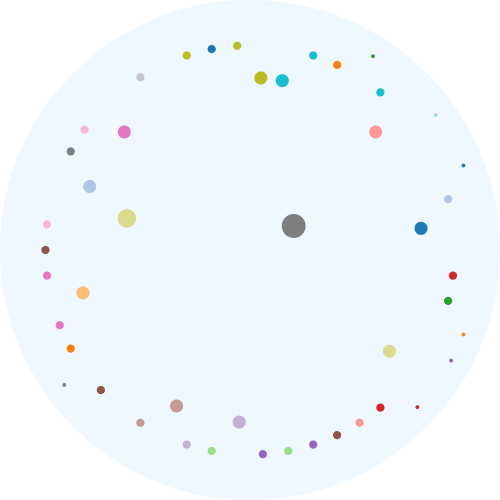

In [6]:
xy_coalescent = coalescent_embedding_2D(G, **embedding_parameters_dict)
plot_Pdisk_embedding_n(xy_coalescent, node_colors=colors, sizes=np.array(N*[0.1]))

In [ ]:
#ind1 = np.argsort(th_G)[0] #the second most central actually
#ind2 = np.argsort(th_G)[3]

# find its nearest points in the original graph embedding
D_matrix = hyp_dist_matrix(Y_G,Y_G)
print(D_matrix)
np.fill_diagonal(D_matrix,0)
#ind_kN = k_argmin(D_matrix[:,ind],k)
#ind_kN = np.setdiff1d(k_argmin(D_matrix[:,ind_most_central],k+1),ind_most_central)

b = 1

indc = np.argsort(r_G)[0] #central
indc_ball =np.where(D_matrix[:,indc]<np.average(D_matrix)/b)[0]
indp = np.argsort(r_G)[12] #peripheric
indp_ball =np.where(D_matrix[:,indp]<np.average(D_matrix)/b)[0]

edgelistc = np.array([[indc,indc_ball[j]] for j in range(len(indc_ball))])
edgelistc_colors = np.array(len(edgelistc)*['#0000EE'])
edgelistp = np.array([[indp,indp_ball[j]] for j in range(len(indp_ball))])
edgelistp_colors = np.array(len(edgelistp)*['#DC143C'])

edgelist = np.append(edgelistc,edgelistp, axis=0)
edgelist_colors = np.append(edgelistc_colors,edgelistp_colors, axis=0)

[[ 0.         37.39009637 41.02225793 ... 45.24592748 45.56330635
  36.00775245]
 [37.39009637  0.         47.2731009  ... 51.38612107 53.42120933
  44.68187729]
 [41.02225793 47.2731009   0.         ... 49.28479045 55.86587787
  47.60722583]
 ...
 [45.24592748 51.38612107 49.28479045 ...  0.         60.17497051
  51.87601406]
 [45.56330635 53.42120933 55.86587787 ... 60.17497051  0.
  50.66840416]
 [36.00775245 44.68187729 47.60722583 ... 51.87601406 50.66840416
   0.        ]]


In [ ]:
## Plot
Y_poincare = native_to_poincare(Y_G)
Y_native_rescaled = native_to_unitnative(Y_G)

# nodes at distance to central nnode
Pdisk_G_c = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelistc, edgelist_colors=edgelistc_colors, sizes=node_sizes)
#Pdisk_G.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-o.svg'%(k))
# nodes at distance to peripheric node
Pdisk_G_p = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelistp, edgelist_colors=edgelistp_colors, sizes=node_sizes)
#Pdisk_G_p.save_svg('/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/media_draw/Pdisk-%iNHD-WS-p%.2f.svg'%(k,mag))
Pdisk_G = plot_Pdisk_embedding(Y_native_rescaled, node_colors=node_colors, edgelist=edgelist, edgelist_colors=edgelist_colors, sizes=node_sizes)

[0.99999995 1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         0.99999995
 1.         1.         1.         0.99999995 0.99680511 1.
 0.99999995 1.         1.         1.         1.         1.
 1.         1.         0.99999995 1.         0.99999995 1.
 0.99999995 1.         0.99999995 1.         1.         0.99999995
 1.         1.         1.         1.         0.99999995 1.
 1.         1.         1.         1.         1.         1.
 1.         1.        ]
[0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.97686999 0.98
 0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.98       0.98
 0.98       0.98       0.98       0.98       0.98       0.98


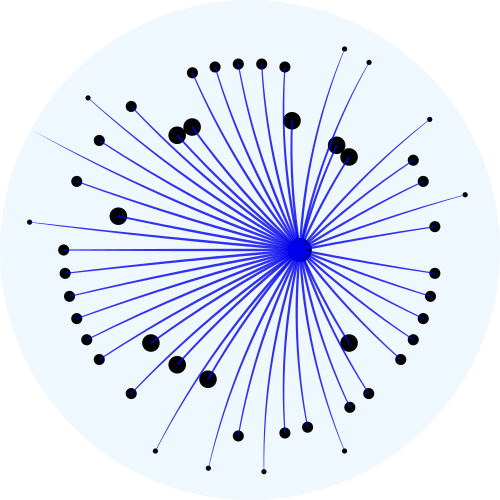

In [ ]:
Pdisk_G_c

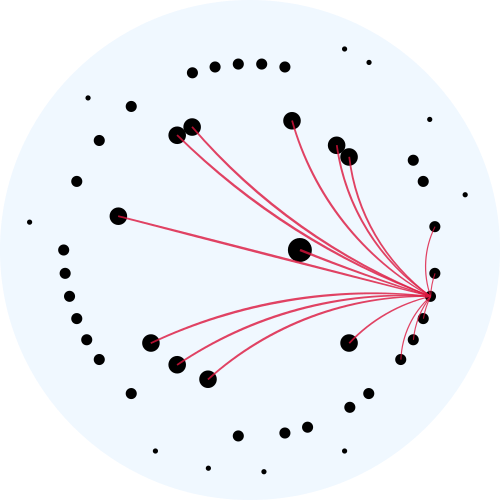

In [ ]:
Pdisk_G_p